In [380]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import importlib

import testis_modeling2 as tm
importlib.reload(tm)

<module 'testis_modeling2' from '/Users/connor/Documents/github/gagnon/testis_modeling2/__init__.py'>

In [431]:
importlib.reload(tm.gillespie)
importlib.reload(tm.data_processing)

n_stem = 1000
n_clones = 2
r_event = 36

p_asymmetric = 18/36

eff_drift = r_event * (1 - p_asymmetric)
p_diff = q_div = (1 - p_asymmetric) / 2

sperm_per_diff = 1300
r_decay = 7

rng = np.random.default_rng()
init_freq = np.array([0.5, 0.5])
hmm = tm.gillespie.AdvancedTestisModel(n_stem, n_clones, r_event, p_diff, q_div, r_decay, sperm_per_diff, init_freq)

In [432]:
sample_times = np.sort(np.array(list(tm.data_processing.sample_map_int.values())))
# sample_times = np.arange(5, 20)
sample_times = np.repeat(sample_times, 3)

In [433]:
# sample_times = np.arange(1, 16)
n_sperm = 371

samples, record, mean = hmm.simulate_gillespie(sample_times, n_sperm = 371, rng = rng, init_time = 4)

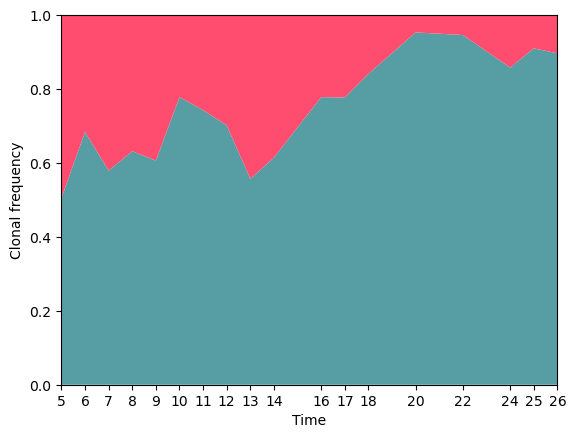

In [434]:
importlib.reload(tm.visualize)
tm.visualize.plot(samples)

In [435]:
importlib.reload(tm.likelihood)
lm = tm.likelihood.LikelihoodModel(n_stem)

In [436]:
# lm.precompute_T(np.logspace(-2, 3, 151))
# ls = lm.likelihood_grid(samples, lm.rs, init_freq[0])

In [437]:
lm.max_likelihood_null(samples, init_time = 4)

/opt/anaconda3/envs/tm/lib/python3.11/site-packages/scipy/optimize/_numdiff.py:596: RuntimeWarning: invalid value encountered in subtract
  df = fun(x1) - f0


(np.float64(0.2577118897873615), np.float64(-1545.5960904358199))

In [438]:
%%time
r_opt, if_opt, l_max, lower, upper = lm.max_likelihood(samples, init_time = 4)
print(f'{r_opt:.3f}, {if_opt:.3f}, {l_max:.3f}, {lower:.3f}, {upper:.3f}')

17.856, 0.491, -223.399, 7.630, 49.620
CPU times: user 32.3 s, sys: 3.94 s, total: 36.2 s
Wall time: 5.01 s


In [351]:
lm.T_cache.keys()

dict_keys([])

In [68]:
if_null, l_null = lm.max_likelihood_null(samples)
print(f'{if_null:.2f}, {l_null:.2f}.')

0.04, -480.28.


In [63]:
l = lm.likelihood(samples, 0, if_null)
print(f'{l:.5f}')

-57.22497


In [69]:
# null2 converges fine when drift is low, breaks when drift is high but at that point it doesnt matter
lm.max_likelihood_null2(samples)

(np.float64(0.04294699011680144), np.float64(-576.4269907908271))

In [228]:
p = samples['obs_result'].apply(lambda x: x[0]).sum() / samples['n_sperm'].sum()

In [231]:
import numpy as np
from scipy.special import gammaln

def binomial_log_likelihood(p, samps, n=371):
    if p <= 0 or p >= 1:
        return -np.inf  # log-likelihood undefined at boundaries

    # Use gammaln for stable log binomial coefficient
    log_coeff = gammaln(n + 1) - gammaln(samps + 1) - gammaln(n - samps + 1)
    log_likelihood = log_coeff + samps * np.log(p) + (n - samps) * np.log(1 - p)
    
    return np.sum(log_likelihood)

In [230]:
samps = np.array(samples['obs_result'].apply(lambda x: x[0]))
samps

array([139, 149, 265, 314, 307, 223, 261, 329, 322, 343, 318, 240, 189,
       235, 335])

In [237]:
binomial_log_likelihood(0.713, samps)

np.float64(-470.049068735225)

In [211]:
l, alpha = lm.likelihood(samples, 0, 0.713, return_alpha=True)
l

np.float64(-522.7046976133672)

In [212]:
alpha.sum(axis=1)

array([1.30445683e-030, 4.02301002e-045, 1.06434627e-051, 7.57206428e-073,
       3.45998006e-087, 2.07651127e-089, 8.69081007e-092, 3.19081550e-116,
       2.21775796e-136, 2.91442846e-170, 3.03426363e-188, 1.23222442e-189,
       2.76387629e-198, 7.94289480e-200, 9.82277422e-228])

In [152]:
np.sum(alpha[-1,:])

np.float64(4.1136370876701306e-110)

In [138]:
lm.max_likelihood_null(samples)

if = 0.50, like = 251.87.
if = 0.50, like = 251.87.
if = 0.09, like = 349.38.
if = 0.09, like = 349.38.
if = 0.36, like = inf.
if = 0.36, like = inf.
if = 0.50, like = 251.87.
if = 0.50, like = 251.87.


/opt/anaconda3/envs/tm/lib/python3.11/site-packages/scipy/optimize/_numdiff.py:596: RuntimeWarning: invalid value encountered in subtract
  df = fun(x1) - f0


(np.float64(0.5), np.float64(-251.87005265598927))

In [118]:
lm.likelihood(samples, 59.51, 0.395)

np.float64(-80.255430844107)

In [119]:
%%time

r_opt, if_opt, l_max = lm.max_likelihood(samples, statistic = None)
print(f'{r_opt:.2f}, {if_opt:.2f}, {l_max:.2f}')

59.51, 0.38, -80.04
CPU times: user 12.5 s, sys: 437 ms, total: 13 s
Wall time: 1.7 s


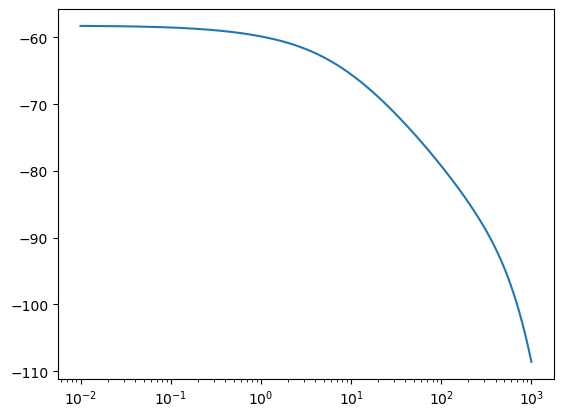

In [407]:
ls = lm.likelihood_grid(samples, lm.rs)
plt.plot(lm.rs, ls)
plt.xscale('log')

In [274]:
%%time

r_opt, l_max, lower, upper = max_likelihood(lm, samples, statistic = 2)
print(f'{r_opt:.2f}, {l_max:.2f}, {lower:.2f}, {upper:.2f}')

31.44, -71.82, 11.60, 111.73
CPU times: user 10.7 s, sys: 1.46 s, total: 12.2 s
Wall time: 1.65 s


In [13]:
def sim_study(r, n_sims):
    n_stem = 1000
    n_clones = 2
    r_event = 36
    
    p_asymmetric = (36 - r) / r_event
    
    eff_drift = r_event * (1 - p_asymmetric)
    p_diff = q_div = (1 - p_asymmetric) / 2
    
    sperm_per_diff = 1300
    r_decay = 6.28
    init_freq = np.array([0.5, 0.5])
    
    n_sperm = 371
    
    hmm = tm.gillespie.AdvancedTestisModel(n_stem, n_clones, r_event, p_diff, q_div, r_decay, sperm_per_diff, init_freq)
    lm = tm.likelihood.LikelihoodModel(n_stem)

    r_maxes = []
    for i in range(n_sims):
        rng = np.random.default_rng(i)
        sample_times = np.arange(1, 16)

        samples, record, mean = hmm.simulate_gillespie(sample_times, n_sperm = n_sperm, rng = rng)
        r_opt, l_max = lm.max_likelihood(samples, statistic = None)
        r_maxes.append(r_opt)

    return np.array(r_maxes)

In [380]:
r_maxes = sim_study(1, 10)

In [14]:
%%time
from joblib import Parallel, delayed

# Define the r values and fixed second argument
r_values = [0.01, 0.1, 1, 10, 36]
n_sims = 100

# Run in parallel
r_maxes = Parallel(n_jobs=-1)(delayed(sim_study)(r, n_sims) for r in r_values)

CPU times: user 283 ms, sys: 192 ms, total: 475 ms
Wall time: 4min 33s


In [17]:
for i in range(len(r_maxes)):
    rm = r_maxes[i]
    print(f'r = {r_values[i]:.2f}:\t {np.mean(rm):.2f} +/- {np.std(rm)/np.sqrt(n_sims):.2f}')

r = 0.01:	 0.12 +/- 0.02
r = 0.10:	 0.31 +/- 0.05
r = 1.00:	 1.06 +/- 0.08
r = 10.00:	 9.05 +/- 0.42
r = 36.00:	 34.73 +/- 2.33


In [419]:
%%time
from joblib import Parallel, delayed

# Define the r values and fixed second argument
r_values = [0.01, 0.1, 1, 10, 36]
n_sims = 500

# Run in parallel
r_maxes = Parallel(n_jobs=-1)(delayed(sim_study)(r, n_sims) for r in r_values)

/Users/connor/Documents/github/gagnon/testis_modeling2/likelihood.py:170: RuntimeWarning: invalid value encountered in log
  l = np.log(np.sum(alpha[-1,:]))
/Users/connor/Documents/github/gagnon/testis_modeling2/likelihood.py:170: RuntimeWarning: invalid value encountered in log
  l = np.log(np.sum(alpha[-1,:]))


CPU times: user 1.53 s, sys: 739 ms, total: 2.27 s
Wall time: 18min 50s


In [420]:
for i in range(len(r_maxes)):
    rm = r_maxes[i]
    print(f'r = {r_values[i]:.2f}:\t {np.mean(rm):.2f} +/- {np.std(rm)/np.sqrt(n_sims):.2f}')

r = 0.01:	 0.12 +/- 0.01
r = 0.10:	 0.18 +/- 0.01
r = 1.00:	 0.97 +/- 0.03
r = 10.00:	 7.63 +/- 0.18
r = 36.00:	 29.13 +/- 0.72


In [430]:
import testis_modeling as tm1

lm1 = tm1.advanced_likelihood2.LikelihoodModel(n_stem)

t_elapsed = 1
r_event = 36

r_diff = 36
p_asymmetric = (36 - r) / r_event
p_diff = (1 - p_asymmetric) / 2

times = np.logspace(-2, 3, 101)
lm1.precompute(times)

(array([[[1.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
          0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
         [1.49786125e+00, 2.00005259e+00, 2.49693663e+00, ...,
          0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
         [1.99474209e+00, 2.49693663e+00, 3.00014303e+00, ...,
          0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
         ...,
         [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
          9.99038987e+02, 9.98532690e+02, 9.98024989e+02],
         [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
          9.98532690e+02, 1.00001973e+03, 9.99512020e+02],
         [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
          0.00000000e+00, 0.00000000e+00, 1.00100000e+03]],
 
        [[8.91250938e-01, 0.00000000e+00, 0.00000000e+00, ...,
          0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
         [1.38900924e+00, 1.89131009e+00, 2.38828349e+00, ...,
          0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       

In [ ]:
lm1.mean_stem

In [ ]:
A = lm1.get_A(t_elapsed, r_event, p_diff)